# The Europe Model: Predicting Air Pollution from the Electricity Mix in European Countries

**The question:** Can we predict how polluted the air is (PM2.5) in **European** countries from how much of their electricity comes from polluting sources, together with which country it is and what year it is?

**What is this notebook for?** It builds the **Europe regional model** (Nhi's part of the project). Its results are meant to be compared with the **world model** (notebook 02), which uses all countries, and with the other regional models. It is the notebook version of `scripts/europe_model.py`: same steps, same settings, same results, with an explanation before every step.

**The plan, in plain English**

1. **Look at the data:** keep only the European countries.
2. **Split by time:** learn from 2000-2018, then be tested on 2019 onwards, like a real forecast.
3. **Set up a fair "practice exam"** (cross-validation) that also respects time: the model is always checked on years *later* than the ones it learned from.
4. **Compare models:** two kinds of model, four sets of inputs, and two very simple "baseline" guesses that any useful model must beat.
5. **Test the chosen model** on 2019+.
6. **Save** the numbers, predictions and charts.

Run it from top to bottom with **Run All**, or one cell at a time with **Shift + Enter**.

### Key terms
| Term | Meaning |
|---|---|
| **PM2.5** | Tiny airborne particles that are harmful to breathe, in micrograms per cubic metre (µg/m³). Lower is better. This is what we **predict** (the *target*). |
| **Emitting share** (`emit`) | The % of a country's electricity that comes from greenhouse-gas-emitting sources (coal, gas and oil). This is the electricity input the project is about. |
| **Features** | The inputs a model uses. Here: the emitting share, the year, and which country the row is about. |
| **Feature set** | A named group of inputs. We compare four (Step 3c). |
| **Regression** | A model that predicts a *number* (here, a PM2.5 level) rather than a category. |
| **Data leakage** | Accidentally letting the model "peek" at information it wouldn't have in real life, which makes results look better than they really are. |
| **Forward-chaining cross-validation** | A practice exam that respects time: learn from the earlier years, check on the following years, then repeat with a longer learning period. The model is never checked on years earlier than the ones it learned from. |
| **One-hot encoding** | A way to turn a category (here, the country name) into numbers: one 0/1 column per country, with a 1 in that country's column (Week 4 lecture). |
| **z-score / normalised units** | A value expressed as "how many standard deviations from the average". It lets errors be compared across regions with different pollution levels. |
| **Baseline** | A deliberately simple guess (e.g. "always predict the average"). A real model is only useful if it beats the baselines. |
| **Persistence** | A baseline that predicts each country's most recent known value: "next year will look like the last year we know about". |
| **Hyper-parameter** | A setting chosen by us before training (e.g. how deep the trees may grow), not learned from the data. |
| **Ablation** | Removing an input and re-scoring, to see how much it really contributed. |

## Step 0 - Load the tools and settings

All the settings are defined in one place here, so teammates can change them without hunting through the code.

- **Training years `2000-2018`, test years `2019` onwards** (up to 2022, the latest year in the data). These years come from the project proposal. The test years are split off first and never used for learning, scaling, choosing a model or cross-validation.
- **`RANDOM_STATE = 42`**: anything random uses this fixed seed, so everyone gets the same results.
- **`CV_FOLDS`**: the three rounds of the time-respecting practice exam (explained in Part 3).
- **`EUROPE`**: our list of European countries. A few are **judgement calls** (keep this list identical across the team): **included** Russia, Turkey and Cyprus; **excluded** Georgia, Armenia, Azerbaijan, Kazakhstan and Greenland.
- **`FEATURE_SETS`**: the four groups of inputs that are compared (explained in Step 3c).
- **Paths**: the notebook runs from the `notebooks/` folder, so the data is in `../data/` and the results go to `../results/europe/` (the same place as the script's).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_FILE = Path("../data/processed/cleaned_climate_merged.csv")
OUT_DIR = Path("../results/europe")   # notebooks run from the notebooks/ folder

TRAIN_START = 2000
TRAIN_END = 2018
TEST_START = 2019  # test = TEST_START .. latest year in the data
RANDOM_STATE = 42

# Forward-chaining CV folds: (last training year, first validation year, last validation year)
CV_FOLDS = [(2008, 2009, 2012), (2012, 2013, 2015), (2015, 2016, 2018)]

# Our definition of "Europe" - keep this identical across the team's notes.
# Included on purpose: Russia, Turkey, Cyprus (judgement calls).
# Excluded on purpose: Georgia, Armenia, Azerbaijan, Kazakhstan, Greenland.
EUROPE = [
    "Albania", "Austria", "Belarus", "Belgium", "Bosnia and Herzegovina",
    "Bulgaria", "Croatia", "Cyprus", "Czechia", "Denmark", "Estonia",
    "Finland", "France", "Germany", "Greece", "Hungary", "Iceland", "Ireland",
    "Italy", "Latvia", "Lithuania", "Luxembourg", "Malta", "Moldova",
    "Montenegro", "Netherlands", "North Macedonia", "Norway", "Poland",
    "Portugal", "Romania", "Russia", "Serbia", "Slovakia", "Slovenia",
    "Spain", "Sweden", "Switzerland", "Turkey", "Ukraine", "United Kingdom",
]

# Feature sets: which columns each candidate model may use.
FEATURE_SETS = {
    "emit only": {"num": ["emit"], "cat": []},
    "emit + year": {"num": ["emit", "year"], "cat": []},
    "emit + year + country": {"num": ["emit", "year"], "cat": ["country"]},
    # ablation: same as above WITHOUT the emitting share, to see what emit adds.
    # It is a control for the report, not an eligible final model (the proposal's
    # model predicts PM2.5 from emitting share, country and year).
    "year + country (no emit)": {"num": ["year"], "cat": ["country"]},
}
ABLATION_SET = "year + country (no emit)"

OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Part 1 - Look at the data first

## Step 1 - Load the data and keep only Europe

This step:

1. **Loads** the cleaned dataset (made by notebook 01).
2. **Checks the columns are what we expect.** If someone opens the CSV in Excel and saves it again, Excel can silently change separators and decimal points and break the file. This check stops with a clear message and tells you how to restore the original.
3. **Gives the columns short names:** `emit` (emitting share), `nonemit` (non-emitting share) and `pm` (PM2.5 exposure).
4. **Keeps only the countries on the `EUROPE` list** and warns if any of them is missing from the data.

In [2]:
def load_europe():
    df = pd.read_csv(DATA_FILE)
    expected = ["country", "year", "% GHG emitting source",
                "% GHG non emitting source", "PM2.5 Exposure"]
    if list(df.columns) != expected:
        raise SystemExit(
            f"{DATA_FILE.name} has unexpected columns: {list(df.columns)}\n"
            "It is probably a corrupted copy (e.g. re-saved by Excel with ';' separators "
            "and mangled decimals).\nRestore the original with:\n"
            "  git checkout main -- data/processed/cleaned_climate_merged.csv"
        )
    df = df.rename(columns={
        "% GHG emitting source": "emit",
        "% GHG non emitting source": "nonemit",
        "PM2.5 Exposure": "pm",
    })
    missing = [c for c in EUROPE if c not in set(df["country"])]
    if missing:
        print(f"WARNING: not in the data (dropped from Europe list): {missing}")
    eu = df[df["country"].isin(EUROPE)].copy()
    return eu.sort_values(["country", "year"]).reset_index(drop=True)


eu = load_europe()
print(f"Countries in Europe list : {eu['country'].nunique()}")
print(f"Rows: {len(eu)}, years {eu['year'].min()}-{eu['year'].max()}")
eu.head()

Countries in Europe list : 41
Rows: 1295, years 1990-2022


,country,year,emit,nonemit,pm
0,Albania,1990,13.636,86.364,23.494610
1,Albania,1991,7.853,92.147,23.067856
2,Albania,1992,5.000,95.000,22.911790
3,Albania,1993,6.232,93.768,22.755726
4,Albania,1994,4.315,95.685,22.599660


# Part 2 - Splitting the data by time

## Step 2 - Learn from 2000-2018, be tested on 2019 onwards

- **Training set:** every European row from **2000 to 2018**. The model learns from these.
- **Test set:** every row from **2019 to 2022**. This is the final exam.

Splitting by **year** rather than at random means the model is tested the way it would be used: predicting years it has never seen.

The cell also prints the average and spread (standard deviation) of PM2.5 in each set, and whether any test country never appears in training. That matters because one of the inputs is the country itself: a model can only use a country it has already seen.

`y_train_std` (the spread of PM2.5 in the training years) is kept for later: errors divided by it give the **normalised** error (see Key terms).

In [3]:
def split_train_test(eu):
    train = eu[(eu["year"] >= TRAIN_START) & (eu["year"] <= TRAIN_END)].reset_index(drop=True)
    test = eu[eu["year"] >= TEST_START].reset_index(drop=True)
    assert train["year"].max() < test["year"].min(), "train/test overlap in time"
    return train, test


train, test = split_train_test(eu)
y_train_std = train["pm"].std()

print(f"Train rows ({TRAIN_START}-{TRAIN_END}) : {len(train)}")
print(f"Test rows  ({TEST_START}-{eu['year'].max()}) : {len(test)}")
print(f"Train PM2.5: mean {train['pm'].mean():.2f}, std {y_train_std:.2f} ug/m3")
print(f"Test  PM2.5: mean {test['pm'].mean():.2f}, std {test['pm'].std():.2f} ug/m3")
unseen = sorted(set(test["country"]) - set(train["country"]))
print(f"Test countries never seen in training: {unseen if unseen else 'none'}")

Train rows (2000-2018) : 774
Test rows  (2019-2022) : 161
Train PM2.5: mean 17.90, std 6.83 ug/m3
Test  PM2.5: mean 13.24, std 5.30 ug/m3
Test countries never seen in training: none


# Part 3 - Comparing models fairly

## Step 3a - A practice exam that respects time (forward-chaining cross-validation)

To choose between models without touching the test set, we hold practice exams inside the training years (**cross-validation**, Week 4 lecture). The lecture's version shuffles the data into random folds. Here that would let the model learn from, say, 2016 and then be quizzed on 2010, i.e. learn from the future. So we use **forward-chaining** folds instead: always learn from the earlier years and check on the next few years.

| Round | Learns from | Checked on |
|---|---|---|
| 1 | 2000-2008 | 2009-2012 |
| 2 | 2000-2012 | 2013-2015 |
| 3 | 2000-2015 | 2016-2018 |

Each round mirrors the real situation of the final test (learn from the past, predict the next years).

> **How this differs from the world model:** notebook 02 groups its folds **by country**, so it checks how well the model handles *countries it has never seen*. This notebook uses the country itself as an input, so every country must be seen in training; its folds instead check how well the model handles *later years of countries it already knows*. The two notebooks therefore answer slightly different questions.

In [4]:
def make_cv_splits(train):
    splits = []
    for last_train, val_start, val_end in CV_FOLDS:
        tr_idx = np.where(train["year"] <= last_train)[0]
        va_idx = np.where((train["year"] >= val_start) & (train["year"] <= val_end))[0]
        splits.append((tr_idx, va_idx))
    return splits


cv_splits = make_cv_splits(train)
for i, (tr, va) in enumerate(cv_splits, 1):
    print(f"CV fold {i}: train years <= {train['year'].iloc[tr].max()} ({len(tr)} rows), "
          f"validate {train['year'].iloc[va].min()}-{train['year'].iloc[va].max()} ({len(va)} rows)")

CV fold 1: train years <= 2008 (364 rows), validate 2009-2012 (164 rows)
CV fold 2: train years <= 2012 (528 rows), validate 2013-2015 (123 rows)
CV fold 3: train years <= 2015 (651 rows), validate 2016-2018 (123 rows)


## Step 3b - Preparing the inputs, without leakage

Before a model sees the data, three preparation steps happen, all bundled into one **Pipeline**:

1. **Scale the numbers** (`StandardScaler`): emitting share and year are put on the same scale, so neither swamps the other.
2. **One-hot encode the country** (`OneHotEncoder`): turns each country name into its own 0/1 column (see Key terms). If a country unknown to the model ever appears, it is simply ignored rather than causing an error.
3. **Normalise the target** (`TransformedTargetRegressor`): PM2.5 is converted to z-scores for learning and converted back to µg/m³ for the predictions.

Because all three live *inside* the pipeline, they are re-learned from the training part of each practice-exam round only, so nothing from the checking years (or the test years) leaks in.

The second cell defines how predictions are scored: **R²**, **MAE** and **RMSE** (as in notebook 02), plus MAE and RMSE in **normalised units** (divided by the spread of PM2.5 in the training years). The scores are always reported separately, never combined into one number.

In [5]:
def make_pipeline(features, estimator):
    transformers = [("num", StandardScaler(), features["num"])]
    if features["cat"]:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), features["cat"]))
    pre = ColumnTransformer(transformers, remainder="drop")
    pipe = Pipeline([("pre", pre), ("est", estimator)])
    # z-score the target using training statistics only
    return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())

In [6]:
def metrics(y_true, y_pred, y_train_std):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mae,
        "RMSE": rmse,
        "MAE_z": mae / y_train_std,
        "RMSE_z": rmse / y_train_std,
    }

## Step 3c - The candidate models and inputs

**Two kinds of model**

- **Ridge regression:** a straight-line model that discourages extreme slopes. Its setting `alpha` (how strongly) is tried at 0.1, 1, 10 and 100.
- **Random Forest:** many decision trees (flowcharts of yes/no questions) whose answers are averaged. Its settings are tried in every combination: tree depth (unlimited, 6 or 12 questions deep) and the minimum number of rows at the end of each branch (1, 3 or 5).

`GridSearchCV` tries **every combination of settings** on the three practice-exam rounds and keeps the one with the lowest average RMSE.

**Four sets of inputs**

| Feature set | Inputs | Role |
|---|---|---|
| `emit only` | emitting share | Can the electricity mix alone predict pollution? |
| `emit + year` | emitting share, year | Adds a general trend over time |
| `emit + year + country` | emitting share, year, country | The model described in the project proposal |
| `year + country (no emit)` | year, country | **Control (ablation):** the same as above *without* the emitting share, to see what the electricity input really adds. It is shown for comparison only and can't be chosen as the final model. |

Every model is tried with every feature set: 8 candidates in total. For each candidate the cell also scores the 2019+ test predictions. **These test scores are for documentation only; the choice is made on cross-validation RMSE alone** (Step 4). This is a difference from notebook 02, which only scores the test set for the chosen model.

This cell takes a little while, because the Random Forest grid has 9 setting combinations × 3 rounds for each feature set.

In [7]:
X_cols = ["country", "year", "emit"]
X_train, y_train = train[X_cols], train["pm"]
X_test, y_test = test[X_cols], test["pm"]

models = {
    "Ridge": (Ridge(), {"regressor__est__alpha": [0.1, 1, 10, 100]}),
    "RandomForest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {
            "regressor__est__max_depth": [None, 6, 12],
            "regressor__est__min_samples_leaf": [1, 3, 5],
        },
    ),
}

rows = []
fitted = {}
for feat_name, features in FEATURE_SETS.items():
    for model_name, (estimator, grid) in models.items():
        search = GridSearchCV(
            make_pipeline(features, estimator),
            param_grid=grid,
            cv=cv_splits,
            scoring="neg_root_mean_squared_error",
            refit=True,
        )
        search.fit(X_train, y_train)
        pred = search.predict(X_test)
        key = f"{model_name} | {feat_name}"
        fitted[key] = (search, pred)
        params = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
        rows.append({
            "model": key,
            "cv_RMSE": -search.best_score_,
            "best_params": str(params),
            **{f"test_{k}": v for k, v in metrics(y_test, pred, y_train_std).items()},
        })
        print(f"done: {key}")

done: Ridge | emit only


done: RandomForest | emit only
done: Ridge | emit + year


done: RandomForest | emit + year
done: Ridge | emit + year + country


done: RandomForest | emit + year + country
done: Ridge | year + country (no emit)


done: RandomForest | year + country (no emit)


## Step 3d - The baselines every model must beat

Two deliberately simple guesses, scored on the same 2019+ test years:

- **Training mean:** predict the average European PM2.5 of 2000-2018 for every row.
- **Persistence:** predict each country's value from its **last training year** (2018). PM2.5 changes slowly, so this is a surprisingly hard baseline to beat: a model that can't beat "same as last time" isn't adding much.

The baselines are only scored on the test set (there's nothing for them to learn or tune), so they have no cross-validation score.

In [8]:
def baseline_predictions(train, test):
    """Simple reference predictions the real models should beat."""
    mean_pred = np.full(len(test), train["pm"].mean())
    # persistence: each country's most recent training-period value
    last = train.sort_values("year").groupby("country")["pm"].last()
    persist_pred = test["country"].map(last).to_numpy()
    return {
        "baseline: training mean": mean_pred,
        "baseline: last training year (persistence)": persist_pred,
    }


for name, pred in baseline_predictions(train, test).items():
    rows.append({
        "model": name, "cv_RMSE": np.nan, "best_params": "-",
        **{f"test_{k}": v for k, v in metrics(y_test, pred, y_train_std).items()},
    })

# Part 4 - Choosing the model

## Step 4 - Pick the lowest cross-validation RMSE

The final model is the candidate with the **lowest cross-validation RMSE**, chosen only from the models that use the emitting share (the proposal's model). The control without the emitting share and the baselines are kept in the table for comparison.

**How to read the table** (sorted with the chosen model first, then by cross-validation RMSE):

| Column | Meaning | Better is |
|---|---|---|
| `cv_RMSE` | Average error on the practice exams, in µg/m³. **This is what the choice is based on.** | Lower |
| `test_R2` | Share of the ups and downs in the 2019+ test years the model explains. 1 = perfect; 0 = no better than always guessing the average; negative = worse than that. | Higher |
| `test_MAE`, `test_RMSE` | Average size of the errors on the test years, in µg/m³ (RMSE counts big misses extra). | Lower |
| `test_MAE_z`, `test_RMSE_z` | The same errors in normalised units (divided by the spread of PM2.5 in the training years). | Lower |
| `selected_by_cv` | `True` for the chosen model. | |

In [9]:
results = pd.DataFrame(rows)
# eligible = fitted models that use the emitting share (the proposal's model);
# the no-emit ablation and the baselines are shown for comparison only.
eligible = results["model"].isin(fitted) & ~results["model"].str.contains(ABLATION_SET, regex=False)
best_key = results[eligible].sort_values("cv_RMSE").iloc[0]["model"]
results["selected_by_cv"] = results["model"] == best_key
results = results.sort_values(["selected_by_cv", "cv_RMSE"], ascending=[False, True])
results.to_csv(OUT_DIR / "europe_results.csv", index=False)

display(results.drop(columns=["best_params"]).round(3))
print(f"Selected model (lowest CV RMSE among models using emitting share): {best_key}")
print("Best params:", results[results["model"] == best_key]["best_params"].iloc[0])

,model,cv_RMSE,test_R2,test_MAE,test_RMSE,test_MAE_z,test_RMSE_z,selected_by_cv
4,Ridge | emit + year + country,1.908,0.860,1.538,1.974,0.225,0.289,True
7,RandomForest | year + country (no emit),1.526,0.812,1.871,2.287,0.274,0.335,False
6,Ridge | year + country (no emit),1.832,0.870,1.482,1.905,0.217,0.279,False
5,RandomForest | emit + year + country,2.061,0.801,1.971,2.354,0.289,0.345,False
3,RandomForest | emit + year,5.680,0.113,4.070,4.972,0.596,0.728,False
2,Ridge | emit + year,5.768,0.168,3.867,4.814,0.567,0.705,False
0,Ridge | emit only,6.467,-0.343,5.307,6.118,0.777,0.896,False
1,RandomForest | emit only,6.836,-0.759,5.830,7.001,0.854,1.026,False
8,baseline: training mean,NaN,-0.778,6.106,7.039,0.895,1.031,False
9,baseline: last training year (persistence),NaN,0.788,2.013,2.431,0.295,0.356,False


Selected model (lowest CV RMSE among models using emitting share): Ridge | emit + year + country
Best params: {'alpha': 1}


## Step 4b - What does the emitting share actually add? (ablation)

Compare the chosen model with the **control** that uses only year and country. If the control scores about as well, then once the model knows *which country* and *which year*, the electricity mix adds little. The country input already captures each country's typical pollution level, and the year input captures the general trend.

In [10]:
ablation_rows = results[results["model"].str.contains(ABLATION_SET, regex=False)]
print("Ablation (no emitting share) test R2 by model:",
      {r["model"].split(" |")[0]: round(r["test_R2"], 3) for _, r in ablation_rows.iterrows()})
print("Selected model test R2:", round(results.loc[results["model"] == best_key, "test_R2"].iloc[0], 3))
print("-> If the ablation matches or beats the selected model, emitting share adds little "
      "once country and year are known.")

Ablation (no emitting share) test R2 by model: {'RandomForest': 0.812, 'Ridge': 0.87}
Selected model test R2: 0.86
-> If the ablation matches or beats the selected model, emitting share adds little once country and year are known.


# Part 5 - The final test

## Step 5 - Score the chosen model on 2019 onwards

The chosen model's predictions for every test row are saved to `europe_test_predictions.csv` (country, year, actual, predicted), so they can be compared or combined with the other models later. Then its final scores are printed.

In [11]:
best_search, best_pred = fitted[best_key]
out = test[["country", "year", "pm"]].rename(columns={"pm": "actual"})
out["predicted"] = best_pred
out.to_csv(OUT_DIR / "europe_test_predictions.csv", index=False)

final = metrics(y_test, best_pred, y_train_std)
print(f"FINAL TEST (selected model: {best_key}, {TEST_START}+ hold-out):")
print(f"  R2   : {final['R2']:.4f}")
print(f"  MAE  : {final['MAE']:.3f} ug/m3   ({final['MAE_z']:.3f} normalised)")
print(f"  RMSE : {final['RMSE']:.3f} ug/m3   ({final['RMSE_z']:.3f} normalised)")

FINAL TEST (selected model: Ridge | emit + year + country, 2019+ hold-out):
  R2   : 0.8601
  MAE  : 1.538 ug/m3   (0.225 normalised)
  RMSE : 1.974 ug/m3   (0.289 normalised)


# Part 6 - Charts

## Step 6a - Chart 1: predicted vs actual

Each dot is one European country-year from the test period. The **horizontal** position is the real PM2.5; the **vertical** position is the model's prediction. The red dashed line is a **perfect** model, so the closer the dots hug it, the better.

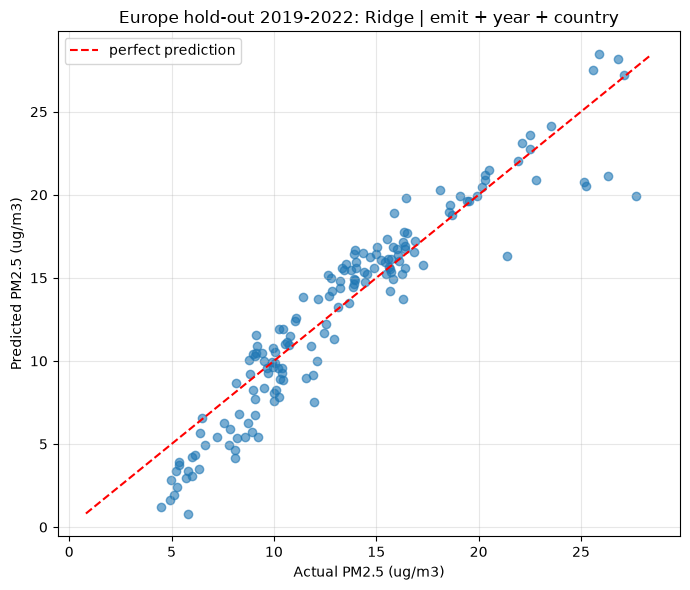

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(out["actual"], out["predicted"], alpha=0.6)
lo = min(out["actual"].min(), out["predicted"].min())
hi = max(out["actual"].max(), out["predicted"].max())
ax.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="perfect prediction")
ax.set_xlabel("Actual PM2.5 (ug/m3)")
ax.set_ylabel("Predicted PM2.5 (ug/m3)")
ax.set_title(f"Europe hold-out {TEST_START}-{eu['year'].max()}: {best_key}")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "europe_actual_vs_predicted.png", dpi=150)
plt.show()

## Step 6b - Chart 2: all candidates compared

The same results as the table, as a picture. **Left:** cross-validation RMSE (what the choice is based on; lower is better). **Right:** test R² on 2019+ (higher is better), including the two baselines. The **chosen model is green**, the **control without the emitting share is grey** and the **baselines are orange**.

*(This chart is only in the notebook; the script doesn't make it.)*

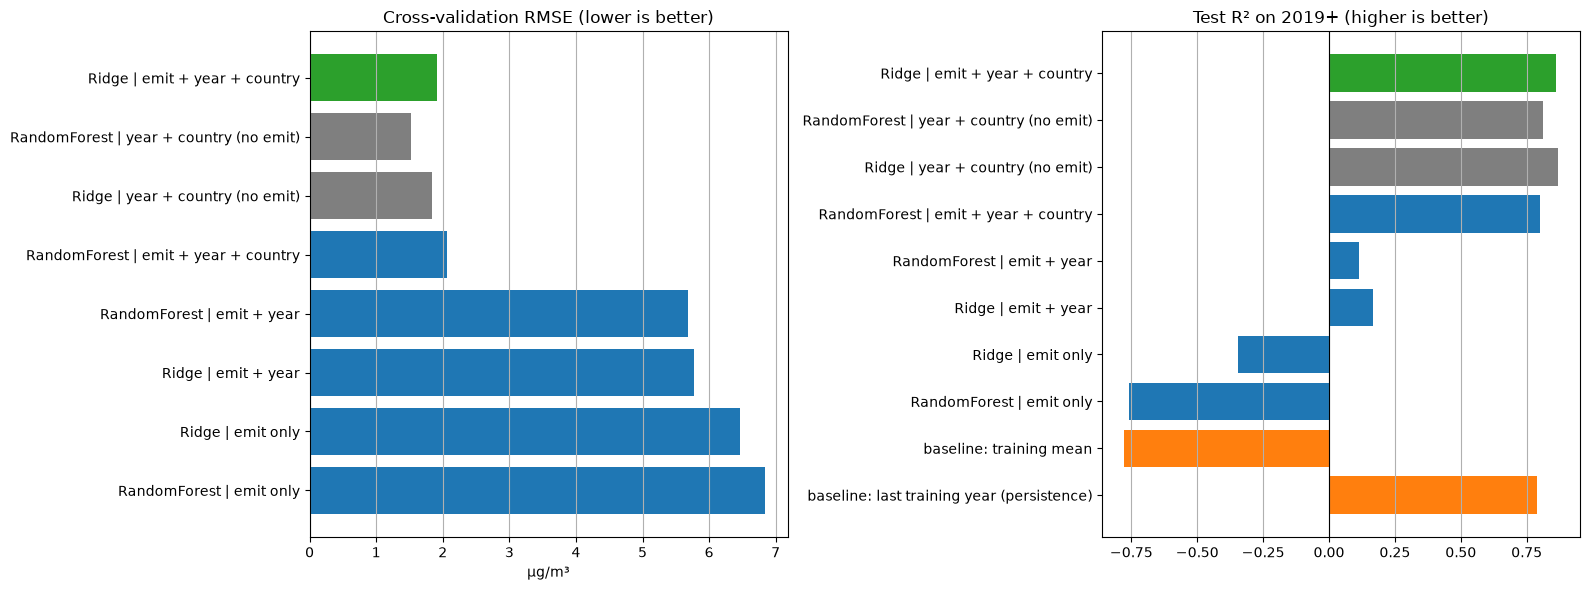

Saved results, predictions and charts to ..\results\europe/


In [13]:
def bar_colour(name):
    if name == best_key:
        return "tab:green"
    if ABLATION_SET in name:
        return "tab:grey"
    if name.startswith("baseline"):
        return "tab:orange"
    return "tab:blue"

fitted_rows = results[results["cv_RMSE"].notna()]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.barh(fitted_rows["model"], fitted_rows["cv_RMSE"], color=[bar_colour(m) for m in fitted_rows["model"]])
ax1.invert_yaxis(); ax1.grid(True, axis="x")
ax1.set(title="Cross-validation RMSE (lower is better)", xlabel="µg/m³")
ax2.barh(results["model"], results["test_R2"], color=[bar_colour(m) for m in results["model"]])
ax2.axvline(0, color="k", linewidth=0.8)
ax2.invert_yaxis(); ax2.grid(True, axis="x")
ax2.set(title=f"Test R² on {TEST_START}+ (higher is better)")
fig.tight_layout()
fig.savefig(OUT_DIR / "europe_model_comparison.png", dpi=150)
plt.show()

print(f"Saved results, predictions and charts to {OUT_DIR}/")

## Summary

*(Numbers quoted here are from the run on 13 October 2026; the tables above update if the data or settings change.)*

- We modelled PM2.5 in **41 European countries**, learning from **2000-2018** and testing on **2019-2022**, with time-respecting cross-validation.
- The chosen model (lowest cross-validation RMSE) was **Ridge regression with emitting share, year and country** (alpha = 1). On the test years it scored **R² 0.86**, with errors of about **1.5 µg/m³ (MAE)** and **2.0 µg/m³ (RMSE)**.
- That beats both baselines: the training average (R² about -0.78) and, more importantly, **persistence** ("same as the country's 2018 value", R² about 0.79).
- **The emitting share adds little.** The control without it (year and country only) scored about the same on the test years: R² about **0.87** with Ridge. In cross-validation, the lowest error of *all* candidates came from the control (Random Forest without the emitting share: 1.53 µg/m³, against 1.91 for the chosen model); it just isn't eligible to be chosen. Almost all of the model's skill comes from **knowing the country** (each country's typical level) and **the year** (the downward trend). The emitting share on its own (`emit only`) does poorly (R² about -0.34).

**Comparing with the world model (notebook 02).** The two notebooks currently use different set-ups, so their scores **can't be compared directly**:

| | World model (notebook 02) | Europe model (this notebook) |
|---|---|---|
| Training years | 1990-2017 | 2000-2018 |
| Test years | 2018-2022 | 2019-2022 |
| Electricity inputs | 19 features (fuel shares, per-person amounts, power-plant emissions) | emitting share only |
| Country as an input | No | Yes |
| Cross-validation | Grouped by country (unseen countries) | Forward-chaining by year (later years of known countries) |
| Question it answers | Predict a country it has never seen | Predict future years of countries it knows |

Knowing the country is a big advantage, which is why the Europe model's R² is much higher. A fair comparison needs the **same test rows, years and inputs**, for example by scoring the world model on just the European test rows, or by giving both models the same split. This should be agreed across the team.

**Limitations**

- Only 41 countries and 4 test years (2022 is missing for 3 countries), so the scores are noisy.
- The Europe list involves judgement calls (Russia, Turkey and Cyprus in; Georgia, Armenia, Azerbaijan, Kazakhstan and Greenland out).
- The test set is scored for every candidate (for documentation). The choice uses cross-validation only, but readers see all test scores, which makes it tempting to pick by test score.
- The model shows **association**, not cause and effect.